# Linear regression as an M-estimator

Passive regression: OLS, PPI, PPI++ and PSPA. Existing binary and continuous **mean** targets remain available. ASI and RASI now also support active regression; see `active_linear_regression.ipynb` for that separate sampling group.

The target is the population least-squares projection on **V = (intercept, X1, ..., X5)**. An independent predictor uses richer **Z = (X, judge scores)**. For this generator the exact target is **beta = (1, 0.8, -0.6, 0, 0, 0)**, despite the nonlinear conditional mean. `focus=1` means the first slope, using zero-based coordinates after intercept insertion.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from openppi import LinearRegression, RegressionData, get_method
from dataset.regression_sim import RegressionDGP
from model.learners import SimulationLearner
from config import Config


## One coefficient fit

The predictor is trained on 400 independent rows. The next 400 rows are labeled inference data; the remaining 1,600 provide predictions and target covariates only. Covariates passed to `RegressionData` exclude the intercept; the target inserts it.


In [2]:
dgp = RegressionDGP(noise='heteroskedastic')
sample = dgp.draw(2400, np.random.default_rng(42))
model = SimulationLearner(Config(outcome_type='continuous', initial_prediction=1.), seed=0)
model.update(sample['features'][:400], sample['y'][:400], sample_weight=np.ones(400))
labeled, unlabeled = slice(400, 800), slice(800, None)
data = RegressionData(
    labels=sample['y'][labeled],
    labeled_predictions=model.predict(sample['features'][labeled]),
    unlabeled_predictions=model.predict(sample['features'][unlabeled]),
    labeled_covariates=sample['x'][labeled],
    unlabeled_covariates=sample['x'][unlabeled])
target = LinearRegression(fit_intercept=True, focus=1)
result = get_method('PPI++').inference(data, target=target, alpha=.05)
low, high = result.confidence_interval
table = pd.DataFrame({'parameter': result.diagnostics['coefficient_names'],
                      'truth': dgp.projection_coefficients(), 'estimate': result.estimate,
                      'SE': result.standard_error, 'lower': low, 'upper': high})
print(table.to_string(index=False))
print('Full covariance matrix:')
print(result.covariance)
print('Tuned prediction weight:', result.diagnostics['prediction_weight'])
print('Supported target/data mapping:', get_method('PPI++').target_data_types)


parameter  truth  estimate       SE     lower     upper
intercept    1.0  1.008837 0.039425  0.931566  1.086107
       V1    0.8  0.852558 0.039073  0.775977  0.929140
       V2   -0.6 -0.524007 0.038525 -0.599515 -0.448500
       V3    0.0  0.010282 0.055663 -0.098815  0.119380
       V4    0.0 -0.034259 0.039146 -0.110983  0.042466
       V5    0.0 -0.023949 0.038836 -0.100066  0.052169
Full covariance matrix:
[[ 1.55430031e-03  4.18133921e-04  1.12097967e-04  5.90588989e-05
   5.11272895e-05 -3.65423707e-05]
 [ 4.18133921e-04  1.52669504e-03  2.10029871e-04  9.45211906e-05
  -4.05780264e-05  1.16488724e-04]
 [ 1.12097967e-04  2.10029871e-04  1.48418205e-03 -1.43797466e-04
   6.56080337e-05  1.81122082e-05]
 [ 5.90588989e-05  9.45211906e-05 -1.43797466e-04  3.09837421e-03
   2.45208543e-04 -1.52424305e-04]
 [ 5.11272895e-05 -4.05780264e-05  6.56080337e-05  2.45208543e-04
   1.53239710e-03  5.01365789e-06]
 [-3.65423707e-05  1.16488724e-04  1.81122082e-05 -1.52424305e-04
   5.01365789

## Estimating equations and reference conventions

PPI/PPI++ solve the rectified squared-loss score equation exactly, with a heteroskedasticity-robust independent-sample sandwich. PPI++ tunes a scalar weight for the focus coefficient and clips to [0,1] for finite-sample convexity. The reference Python package uses a sum of two OLS fits; finite-sample answers can differ on unmatched empirical designs.

PSPA retains the official coordinate weights and one-step point update. Its covariance uses the actual weighted score covariance with both transpose cross-terms; the nonsymmetric multivariate cross-term in the reference R code is not copied. PSPA's vector weights are not retuned to a single focus coefficient.

Intervals are **pointwise**, not simultaneous. Rank-deficient or ill-conditioned designs are rejected rather than silently regularized.


## Repeated coefficient experiments

Regenerate from the repository root:
```sh
python examples/simulation/regression.py --target linear --focus 1 --reps 100
```

Both noise settings use 100 independent repetitions, 400 predictor-training labels, 400 inference labels and 1,600 unlabeled rows. All four methods share the same target covariates, predictor and inference samples. The target's nonlinear residual contributes to sandwich uncertainty; no homoskedastic model-based OLS variance is assumed.


In [3]:
results_dir = Path('results_linear_regression')
summary = pd.read_csv(results_dir / 'summary.csv')
summary = summary[summary.group == 'given_labels']
supplement = pd.read_csv(results_dir / 'all_coefficients.csv')
supplement = supplement[supplement.group == 'given_labels']
settings = json.loads((results_dir / 'config.json').read_text())
print('Focus coordinate:', settings['focus'], 'true value:', settings['truth'][settings['focus']])
print(summary[['case','method','coverage','mean_width','bias','rmse','actual_labels','training_labels','total_labels']].to_string(index=False))


Focus coordinate: 1 true value: 0.8
           case method  coverage  mean_width      bias     rmse  actual_labels  training_labels  total_labels
  homoskedastic    OLS      0.94    0.146834 -0.001179 0.037625          400.0            400.0         800.0
  homoskedastic    PPI      0.91    0.150709  0.003068 0.043183          400.0            400.0         800.0
  homoskedastic  PPI++      0.95    0.131782  0.002122 0.034613          400.0            400.0         800.0
  homoskedastic   PSPA      0.95    0.131769  0.001286 0.034332          400.0            400.0         800.0
heteroskedastic    OLS      0.94    0.173953  0.000018 0.045231          400.0            400.0         800.0
heteroskedastic    PPI      0.91    0.180199  0.000122 0.053246          400.0            400.0         800.0
heteroskedastic  PPI++      0.90    0.161528  0.000437 0.046017          400.0            400.0         800.0
heteroskedastic   PSPA      0.90    0.161301  0.000149 0.045894          400.0      

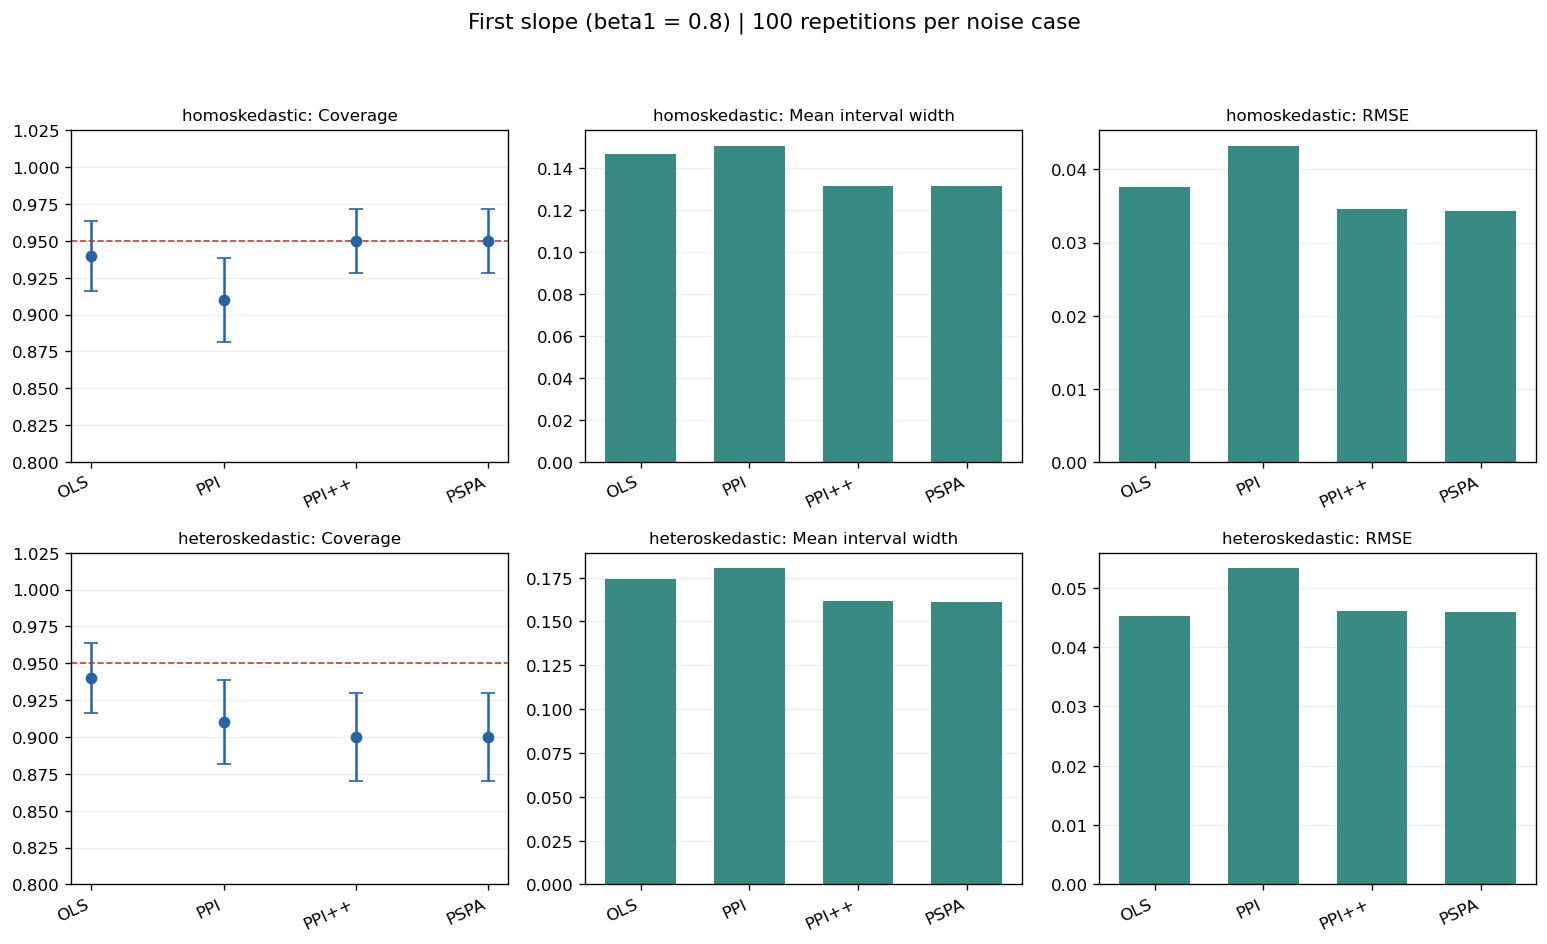

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, noise in enumerate(('homoskedastic', 'heteroskedastic')):
    subset = summary[summary.case == noise]
    x = np.arange(len(subset))
    for col, (metric, title) in enumerate([('coverage','Coverage'), ('mean_width','Mean interval width'), ('rmse','RMSE')]):
        ax = axes[row, col]
        if metric == 'coverage':
            ax.errorbar(x, subset.coverage, yerr=subset.coverage_mc_se, fmt='o', capsize=4, color='#2563a6')
            ax.axhline(.95, linestyle='--', linewidth=1, color='#b6453b')
            ax.set_ylim(.8, 1.025)
        else:
            ax.bar(x, subset[metric], color='#388b83', width=.65)
            ax.set_ylim(bottom=0)
        ax.set_xticks(x, subset.method, rotation=25, ha='right')
        ax.set_title(f'{noise}: {title}', fontsize=10)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
fig.suptitle('First slope (beta1 = 0.8) | 100 repetitions per noise case', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .94))
fig.savefig(results_dir / 'focus_coefficient.png', dpi=150, bbox_inches='tight')
plt.show()


Coverage error bars show one Monte Carlo standard error. In these 100 repetitions some coverage estimates are 0.90–0.91, so narrower intervals are not by themselves evidence of improved inference. More repetitions and finite-sample investigation are needed before making efficiency or coverage claims. The full table preserves bias, RMSE and costs rather than ranking methods only by width.

## All-coefficient supplement

`all_coefficients.csv` reports every coordinate. `per_rep.csv` also stores one JSON covariance row per coefficient; grouping by case/rep/method reconstructs the full covariance matrix. No multiple-testing adjustment is applied.


In [5]:
print(supplement[['case','method','parameter','truth','coverage','mean_width','bias','rmse']].to_string(index=False))


           case method parameter  truth  coverage  mean_width      bias     rmse
  homoskedastic    OLS intercept    1.0      0.91    0.147579 -0.005528 0.040163
  homoskedastic    OLS        V1    0.8      0.94    0.146834 -0.001179 0.037625
  homoskedastic    OLS        V2   -0.6      0.92    0.146822 -0.003173 0.042708
  homoskedastic    OLS        V3    0.0      0.96    0.256935  0.009364 0.061482
  homoskedastic    OLS        V4    0.0      0.93    0.145991 -0.000275 0.038286
  homoskedastic    OLS        V5    0.0      0.97    0.147044 -0.005430 0.037108
  homoskedastic    PPI intercept    1.0      0.93    0.140649 -0.004328 0.039082
  homoskedastic    PPI        V1    0.8      0.91    0.150709  0.003068 0.043183
  homoskedastic    PPI        V2   -0.6      0.95    0.148947 -0.001757 0.042374
  homoskedastic    PPI        V3    0.0      0.98    0.181478  0.006395 0.043790
  homoskedastic    PPI        V4    0.0      0.97    0.140466 -0.006095 0.035983
  homoskedastic    PPI      